<a href="https://colab.research.google.com/github/MariaVrett/Timeseries-Forecasting/blob/main/Timeseries_Forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import Libraries

In [49]:
import holidays
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import yfinance as yf
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.stattools import grangercausalitytests, adfuller, kpss

# Download Financial Data

Download 10 years of USD Index. Columns Volume, Dividends and Stock Splits are not required, since they are constant and equal to 0.0

In [50]:
ticker_symbol = 'DX-Y.NYB'

ticker = yf.Ticker(ticker_symbol)
df = ticker.history(period='10y').drop(columns=['Volume', 'Dividends', 'Stock Splits']).reset_index(drop=False)
df

,Date,Open,High,Low,Close
0,2016-10-31 00:00:00-04:00,98.320000,98.699997,98.290001,98.449997
1,2016-11-01 00:00:00-04:00,98.389999,98.480003,97.639999,97.699997
2,2016-11-02 00:00:00-04:00,97.750000,97.800003,97.180000,97.400002
3,2016-11-03 00:00:00-04:00,97.379997,97.459999,97.040001,97.160004
4,2016-11-04 00:00:00-04:00,97.160004,97.349998,96.889999,97.070000
...,...,...,...,...,...
2509,2026-10-23 00:00:00-04:00,101.570000,101.849998,101.489998,101.809998
2510,2026-10-26 00:00:00-04:00,101.779999,102.059998,101.580002,101.959999
2511,2026-10-27 00:00:00-04:00,102.029999,102.400002,101.989998,102.320000
2512,2026-10-28 00:00:00-04:00,102.370003,102.489998,102.050003,102.190002


# Construct Line Plot of HLC Data

OHLCV: Stands for Open (Opening price of the day), High (Highest price during the day), Low (Lowest price during the day), Close (Closing price of the day), and Volume (Number of shares traded).

Mean: The average of the values (sum of all values divided by their count).

Standard Deviation: Measures the dispersion or variability of the data around the mean. A low standard deviation means values are clustered close to the mean, while a high one indicates heavy fluctuations.

In [51]:
fig = px.line(df, x='Date', y=['High', 'Close', 'Low'], title='USD Price Index from 2016 to 2026')
fig.update_layout(
    height=600
)
fig.show()

We can see from the line plot that the timeseries are non-stationary. A time series is stationary when its statistical properties (such as mean and variance) remain constant over time. In the graph, we observe long-term trends (upward and downward periods), meaning the mean changes depending on the time period we are examining.

# ADF and KPSS statistics

In [52]:
adf_result = adfuller(df['Close'],result_object=True)
print(f"ADF Statistic: {adf_result[0]:.4f}")
print(f"ADF p-value: {adf_result[1]:.4f}")

kpss_result = kpss(df['Close'], regression='c',result_object=True)
print(f"\nKPSS Statistic: {kpss_result[0]:.4f}")
print(f"KPSS p-value: {kpss_result[1]:.4f}")

ADF Statistic: -1.8958
ADF p-value: 0.3340

KPSS Statistic: 2.8368
KPSS p-value: 0.0100


/tmp/ipykernel_747/3630931315.py:5: InterpolationWarning:

The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.



For the ADF test, the p-value is greater than 0.05, so we fail to reject the null hypothesis (the series has a unit root and is non-stationary).
For the KPSS test, the p-value is less than 0.05, so we reject the null hypothesis of stationarity.
So the time series is non-stationary.

# Train-Test Split

In [53]:
train_size = 0.7
history_size = 30

num_train_samples = int(df.shape[0]*train_size)
train_df = df.iloc[:num_train_samples]
test_df = df.iloc[num_train_samples - history_size:]

train_df.shape, test_df.shape

((1759, 5), (785, 5))

# Construct Timeframes

In [54]:
def construct_timeframes(df, H):
    inputs = df.drop(columns=['Date']).to_numpy(dtype=np.float64)
    x = np.array([inputs[i-H: i].flatten() for i in range(H, df.shape[0])])
    y = df['Close'].to_numpy(dtype=np.float64)[H:]
    return x, y

# Verify Timeframes

In [55]:
train_df.head(5)

,Date,Open,High,Low,Close
0,2016-10-31 00:00:00-04:00,98.320000,98.699997,98.290001,98.449997
1,2016-11-01 00:00:00-04:00,98.389999,98.480003,97.639999,97.699997
2,2016-11-02 00:00:00-04:00,97.750000,97.800003,97.180000,97.400002
3,2016-11-03 00:00:00-04:00,97.379997,97.459999,97.040001,97.160004
4,2016-11-04 00:00:00-04:00,97.160004,97.349998,96.889999,97.070000


In [56]:
x_train, y_train = construct_timeframes(train_df, H=4)
print('x:', x_train[0],'\ny:', y_train[0])

x: [98.31999969 98.69999695 98.29000092 98.44999695 98.38999939 98.48000336
 97.63999939 97.69999695 97.75       97.80000305 97.18000031 97.40000153
 97.37999725 97.45999908 97.04000092 97.16000366] 
y: 97.06999969482422


# Fit Linear Regression Model


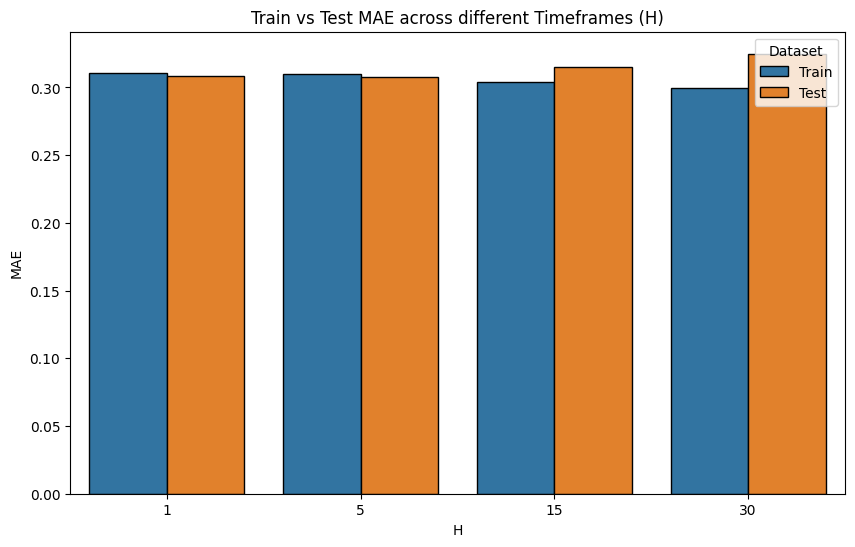

In [57]:
H_values = [1, 5, 15, 30]
results = []

pred_h30 = {}

for h in H_values:
    x_tr, y_tr = construct_timeframes(train_df, h)
    x_te, y_te = construct_timeframes(test_df, h)

    model_h = LinearRegression()
    model_h.fit(x_tr, y_tr)

    pred_tr = model_h.predict(x_tr)
    pred_te = model_h.predict(x_te)

    results.append({'H': str(h), 'Dataset': 'Train', 'MAE': mean_absolute_error(y_tr, pred_tr)})
    results.append({'H': str(h), 'Dataset': 'Test', 'MAE': mean_absolute_error(y_te, pred_te)})

    if h == 30:
        pred_h30['y_train'] = y_tr
        pred_h30['y_test'] = y_te
        pred_h30['pred_te'] = pred_te


metrics_h_df = pd.DataFrame(results)
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=metrics_h_df, x='H', y='MAE', hue='Dataset', edgecolor='black')
ax.set_title('Train vs Test MAE across different Timeframes (H)')
plt.show()

# Visualize Predictions for H = 30

In [58]:
train_dates = train_df['Date'].iloc[history_size:]
test_dates = test_df['Date'].iloc[history_size:]

y_train_30 = pred_h30['y_train']
y_test_30 = pred_h30['y_test']
y_pred_30 = pred_h30['pred_te']

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=train_dates.iloc[-history_size:],
    y=np.ravel(y_train_30)[-history_size:],
    mode='lines',
    name='Train',
    line=dict(color='royalblue', width=2)
))

fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(y_test_30),
    mode='lines',
    name='Test (Actual)',
    line=dict(color='royalblue', width=2, dash='dash')
))

fig.add_shape(
    type='line',
    x0=test_dates.iloc[0],
    x1=test_dates.iloc[0],
    y0=df['Close'].min(),
    y1=df['Close'].max(),
    line=dict(color='black', width=2, dash='dash')
)

fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(y_pred_30),
    mode='lines',
    name='Test (Predicted)',
    line=dict(color='#E63946', width=2.5)
))

fig.update_layout(
    title='USD Price Index — Close Price Prediction',
    xaxis_title='Date',
    yaxis_title='Price ($)',
    template='plotly_white',
    legend=dict(x=0.01, y=0.99),
    hovermode='x unified'
)

fig.show()

The predicted values closely follow the actual values.

# Apply Log Returns Transformation

In [59]:
vars = ['Open', 'High', 'Low', 'Close']
df_logr = df.copy()
df_logr[vars] = np.log(df_logr[vars]/df_logr[vars].shift(1))
df_logr

,Date,Open,High,Low,Close
0,2016-10-31 00:00:00-04:00,NaN,NaN,NaN,NaN
1,2016-11-01 00:00:00-04:00,0.000712,-0.002231,-0.006635,-0.007647
2,2016-11-02 00:00:00-04:00,-0.006526,-0.006929,-0.004722,-0.003075
3,2016-11-03 00:00:00-04:00,-0.003792,-0.003483,-0.001442,-0.002467
4,2016-11-04 00:00:00-04:00,-0.002262,-0.001129,-0.001547,-0.000927
...,...,...,...,...,...
2509,2026-10-23 00:00:00-04:00,-0.001377,-0.000294,0.000394,0.001966
2510,2026-10-26 00:00:00-04:00,0.002065,0.002060,0.000886,0.001472
2511,2026-10-27 00:00:00-04:00,0.002453,0.003326,0.004028,0.003525
2512,2026-10-28 00:00:00-04:00,0.003327,0.000878,0.000588,-0.001271


# Convert Log Returns to Absolute Price

In [60]:
def log_returns_to_absolute_prices(prices, log_returns):
    return prices * np.exp(log_returns)

valid_df = pd.DataFrame({
    'Date': df['Date'].iloc[: 6],
    'Close': df['Close'].iloc[: 6],
    'CLose-Log-Returns': df_logr['Close'].iloc[: 6]
})
valid_df

,Date,Close,CLose-Log-Returns
0,2016-10-31 00:00:00-04:00,98.449997,NaN
1,2016-11-01 00:00:00-04:00,97.699997,-0.007647
2,2016-11-02 00:00:00-04:00,97.400002,-0.003075
3,2016-11-03 00:00:00-04:00,97.160004,-0.002467
4,2016-11-04 00:00:00-04:00,97.070000,-0.000927
5,2016-11-07 00:00:00-05:00,97.779999,0.007288


In [61]:
log_returns_to_absolute_prices(
    prices=valid_df['Close'].iloc[: -1].to_numpy(),
    log_returns=valid_df['CLose-Log-Returns'].iloc[1:].to_numpy()
)

array([97.69999695, 97.40000153, 97.16000366, 97.06999969, 97.77999878])

# Evaluate Log-Returns Model

In [62]:
df_logr_clean = df_logr.dropna().reset_index(drop=True)

df_logr_clean['Prev_Close'] = df['Close'].shift(1).dropna().reset_index(drop=True)
df_logr_clean['Target_Close'] = df['Close'].iloc[1:].reset_index(drop=True)

train_df_logr = df_logr_clean.iloc[:num_train_samples]
test_df_logr = df_logr_clean.iloc[num_train_samples - history_size:]

log_results = []

for h in H_values:
    x_tr_log, y_tr_log = construct_timeframes(train_df_logr.drop(columns=['Prev_Close', 'Target_Close']), h)
    x_te_log, y_te_log = construct_timeframes(test_df_logr.drop(columns=['Prev_Close', 'Target_Close']), h)

    model_log = LinearRegression()
    model_log.fit(x_tr_log, y_tr_log)

    pred_te_log = model_log.predict(x_te_log)

    actual_prev_prices = test_df_logr['Prev_Close'].to_numpy()[h:]
    actual_target_prices = test_df_logr['Target_Close'].to_numpy()[h:]

    predicted_abs_prices = log_returns_to_absolute_prices(actual_prev_prices, pred_te_log)

    mae_abs = mean_absolute_error(actual_target_prices, predicted_abs_prices)
    log_results.append({'H': str(h), 'Log-Return Converted MAE': mae_abs})

log_metrics_df = pd.DataFrame(log_results)

# Compare with standard Absolute Model MAE
comparison_df = pd.merge(
    metrics_h_df[metrics_h_df['Dataset'] == 'Test'][['H', 'MAE']].rename(columns={'MAE': 'Standard Model MAE'}),
    log_metrics_df,
    on='H'
)
comparison_df

,H,Standard Model MAE,Log-Return Converted MAE
0,1,0.308306,0.307369
1,5,0.307977,0.306773
2,15,0.314967,0.314241
3,30,0.324936,0.323021


# Granger Causality Test

In [63]:
data = train_df[['Close', 'Open']]
data = np.log(data/data.shift(1)).dropna()
results = grangercausalitytests(data[['Close', 'Open']], maxlag=history_size)

p_values = {
    lag: results[lag][0]['ssr_ftest'][1]
    for lag in range(1, history_size + 1)
}
results_df = pd.DataFrame({'Lag (H)': list(p_values.keys()), 'P-value': list(p_values.values())})
results_df['Significant'] = results_df['P-value'] < 0.05
results_df

,Lag (H),P-value,Significant
0,1,0.191609,False
1,2,0.820257,False
2,3,0.525268,False
3,4,0.785338,False
4,5,0.025691,True
5,6,0.636667,False
6,7,0.725205,False
7,8,0.392926,False
8,9,0.278278,False
9,10,0.493648,False


The time steps (lags) that are statistically significant for predicting the 'Close' price using the 'Open' price are those where `Significant == True` (i.e., P-value < 0.05). By looking at the dataframe output above, we can identify exactly which specific lags provide useful predictive information.

# Extracting Temporal Features, S&P500 and Enhanced Forecasting

In [64]:
df['Month'] = df['Date'].dt.month
df['DayOfWeek'] = df['Date'].dt.dayofweek  # Monday=0, Sunday=6

us_holidays = holidays.country_holidays('US')
nyse_holidays = holidays.financial_holidays('NYSE')

# Global events
global_events = {
    'NewYearsDay': (1, 1),
    'ValentinesDay': (2, 14),
    'WomensDay': (3, 8),
    'AprilFools': (4, 1),
    'EarthDay': (4, 22),
    'LabourDay': (5, 1),
    'EnvironmentDay': (6, 5),
    'Halloween': (10, 31),
    'ChristmasEve': (12, 24),
    'ChristmasDay': (12, 25),
    'BoxingDay': (12, 26),
    'NewYearsEve': (12, 31),
}

event_dates = set(global_events.values())

df['IsHoliday'] = df['Date'].dt.date.map(
    lambda d: int(
        d in us_holidays
        or d in nyse_holidays
        or (d.month, d.day) in event_dates
    )
)
df['Date'] = pd.to_datetime(df['Date']).dt.tz_localize(None)

sp500 = yf.Ticker('^GSPC').history(period='10y')[['Close']].rename(columns={'Close': 'SP500'})
sp500.index = sp500.index.tz_localize(None) # Match timezone naive
sp500 = sp500.reset_index()
df_enhanced = pd.merge(df, sp500, on='Date', how='left')

df_enhanced['SP500'] = df_enhanced['SP500'].ffill()
df_enhanced = df_enhanced.dropna().reset_index(drop=True)

def construct_timeframes_advanced(df_enh, H):
    past_columns = ['Open', 'High', 'Low', 'Close', 'SP500']
    future_columns = ['Month', 'DayOfWeek', 'IsHoliday']

    past_data = df_enh[past_columns].to_numpy(dtype=np.float64)
    future_data = df_enh[future_columns].to_numpy(dtype=np.float64)
    y_data = df_enh['Close'].to_numpy(dtype=np.float64)

    x_list, y_list = [], []

    for i in range(H, len(df_enh)):
        past_window = past_data[i-H : i].flatten()
        future_known = future_data[i]
        combined_features = np.concatenate([past_window, future_known])

        x_list.append(combined_features)
        y_list.append(y_data[i])

    return np.array(x_list), np.array(y_list)

num_train_enh = int(df_enhanced.shape[0] * train_size)
train_df_enh = df_enhanced.iloc[:num_train_enh]
test_df_enh = df_enhanced.iloc[num_train_enh - history_size:]

x_train_enh, y_train_enh = construct_timeframes_advanced(train_df_enh, 30)
x_test_enh, y_test_enh = construct_timeframes_advanced(test_df_enh, 30)

model_enh = LinearRegression()
model_enh.fit(x_train_enh, y_train_enh)

y_pred_enh = model_enh.predict(x_test_enh)

test_dates_enh = test_df_enh['Date'].iloc[30:]

fig2 = go.Figure()

fig2.add_trace(go.Scatter(
    x=test_dates_enh, y=y_test_enh,
    mode='lines', name='Test (Actual)',
    line=dict(color='royalblue', width=2, dash='dash')
))

fig2.add_trace(go.Scatter(
    x=test_dates_enh, y=y_pred_enh,
    mode='lines', name='Test (Predicted - Enhanced Features)',
    line=dict(color='#E63946', width=2.5)
))

fig2.update_layout(
    title='USD Price Index Prediction with SP500 and Future Temporal Features (H=30)',
    xaxis_title='Date', yaxis_title='Price ($)',
    template='plotly_white', legend=dict(x=0.01, y=0.99), hovermode='x unified'
)

fig2.show()